# Module 2 (CO2): AML Domain Feature Engineering & Typology Extraction
**Project**: Anti-Money Laundering Detection (IBM Benchmark)
**Focus**: Extracting multi-bank network features and account volatility metrics.

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(r'../data/ibm_aml_transactions.csv')
df['Timestamp'] = pd.to_datetime(df['Timestamp'])

# 1. Relational Banking Features
df['is_cross_bank'] = (df['From Bank'] != df['To Bank']).astype(int)
df['is_currency_conversion'] = (df['Receiving Currency'] != df['Payment Currency']).astype(int)
df['amount_diff'] = np.abs(df['Amount Paid'] - df['Amount Received'])

# 2. Account Historical Baseline Statistics
sender_stats = df.groupby('Account')['Amount Paid'].agg(
    sender_tx_count='count',
    sender_mean_amount='mean',
    sender_std_amount='std'
).reset_index().fillna(0)
df = df.merge(sender_stats, on='Account', how='left')

# 3. Ratio & Z-Score Anomaly Metrics
df['amount_to_sender_mean'] = df['Amount Paid'] / (df['sender_mean_amount'] + 1e-5)
df['sender_amount_zscore'] = (df['Amount Paid'] - df['sender_mean_amount']) / (df['sender_std_amount'] + 1e-5)

# 4. Structuring Detection (Amounts between $8,500 and $9,999)
df['structuring_flag'] = ((df['Amount Paid'] >= 8500) & (df['Amount Paid'] < 10000)).astype(int)

# 5. Timing Indicators
df['hour'] = df['Timestamp'].dt.hour
df['dayofweek'] = df['Timestamp'].dt.dayofweek
df['is_night'] = df['hour'].isin([0, 1, 2, 3, 4, 5, 22, 23]).astype(int)

print("Engineered Banking Feature Matrix Shape:", df.shape)
df[['From Bank', 'To Bank', 'Amount Paid', 'amount_diff', 'is_cross_bank', 'sender_amount_zscore', 'structuring_flag', 'Is Laundering']].head(10)

Engineered Banking Feature Matrix Shape: (100000, 23)


,From Bank,To Bank,Amount Paid,amount_diff,is_cross_bank,sender_amount_zscore,structuring_flag,Is Laundering
0,701,1853,1688.21,0.0,1,0.000000,0,0
1,12,32564,36107.76,0.0,1,0.000000,0,0
2,24840,23691,2963.72,0.0,1,1.149885,0,0
3,5627,18067,8500.01,0.0,1,0.000000,1,0
4,133452,133686,5157.01,0.0,1,0.000000,0,0
5,1299,1299,11398.17,0.0,0,0.000000,0,0
6,1674,143947,2152.75,0.0,1,-0.707107,0,0
7,118,38478,5215.10,0.0,1,-0.701957,0,0
8,70,25534,2812.56,0.0,1,-0.151578,0,0
9,13037,121698,2793.61,0.0,1,1.078950,0,0


## 2. Visualization: Engineered Typology Distributions

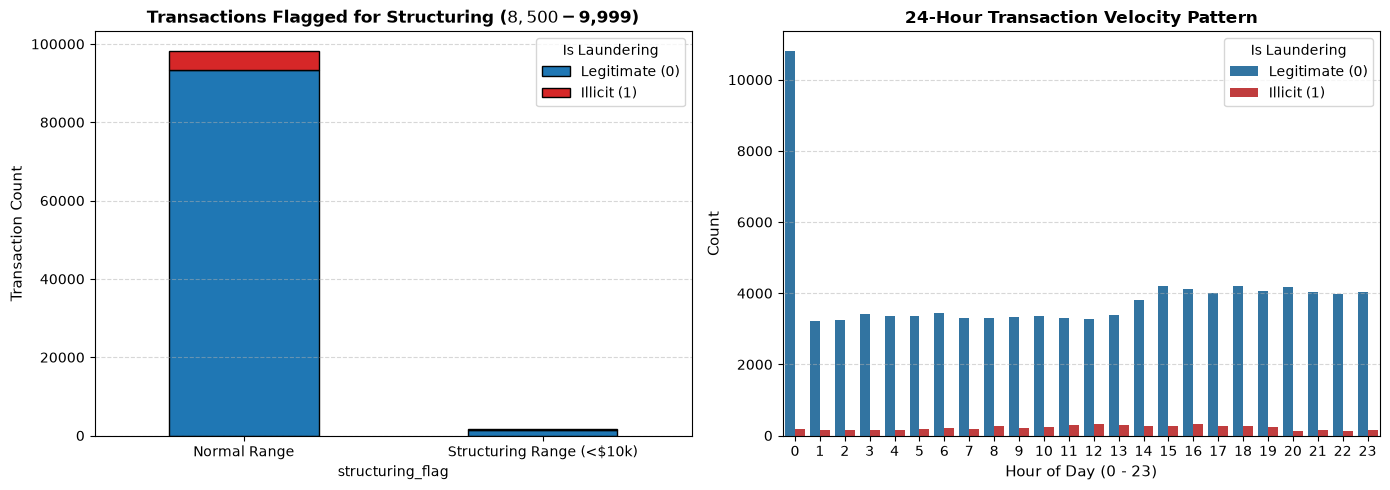

In [2]:
# Visualization: Structuring / Smurfing Typology Detection
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Structuring Flag Distribution vs Laundering
struct_df = df.groupby(['structuring_flag', 'Is Laundering']).size().unstack().fillna(0)
struct_df.plot(kind='bar', stacked=True, color=['#1f77b4', '#d62728'], ax=axes[0], edgecolor='black')
axes[0].set_title('Transactions Flagged for Structuring ($8,500 - $9,999)', fontsize=12, fontweight='bold')
axes[0].set_xticklabels(['Normal Range', 'Structuring Range (<$10k)'], rotation=0)
axes[0].set_ylabel('Transaction Count', fontsize=11)
axes[0].legend(title='Is Laundering', labels=['Legitimate (0)', 'Illicit (1)'])
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 2. Hourly Velocity by Class
sns.countplot(data=df, x='hour', hue='Is Laundering', palette=['#1f77b4', '#d62728'], ax=axes[1])
axes[1].set_title('24-Hour Transaction Velocity Pattern', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hour of Day (0 - 23)', fontsize=11)
axes[1].set_ylabel('Count', fontsize=11)
axes[1].legend(title='Is Laundering', labels=['Legitimate (0)', 'Illicit (1)'])
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
